In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import control as ct
import scipy.signal as signal

In [2]:
K = 8
G1 = ct.tf([1, 2], [1, 1])
G2 = ct.tf([1], [1, 4])
G3 = 1

# Gain of the system K 
print(f'The gain of the system K: {K}')

# Actual Plant 
G = K * G1 * G2 * G3
print(f'The transfer function of the system G(s): {G}')

# Feedback Loop Transfer Function
H = 1 
print(f'The transfer function of the feedback loop H(s): {H}')

# Open Loop Transfer Funtion 
L = G * H
print(f'The transfer function of the open loop system L(s): {L}')

# Closed Loop Transfer Funtion
CL = ct.feedback(G, H)
print(f'The transfer function of the closed loop system CL(s): {CL}')

The gain of the system K: 8
The transfer function of the system G(s): <TransferFunction>: sys[6]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

    8 s + 16
  -------------
  s^2 + 5 s + 4
The transfer function of the feedback loop H(s): 1
The transfer function of the open loop system L(s): <TransferFunction>: sys[8]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

    8 s + 16
  -------------
  s^2 + 5 s + 4
The transfer function of the closed loop system CL(s): <TransferFunction>: sys[10]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

     8 s + 16
  ---------------
  s^2 + 13 s + 20


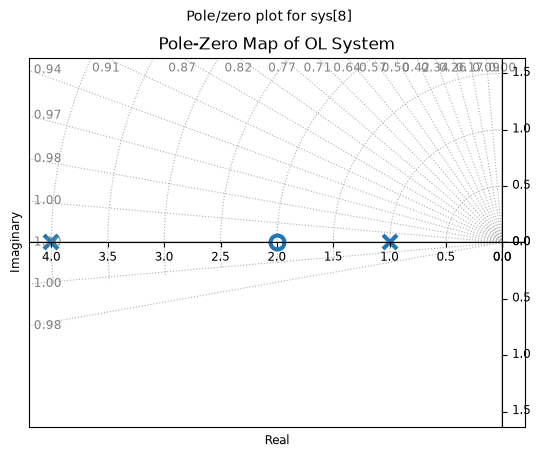

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


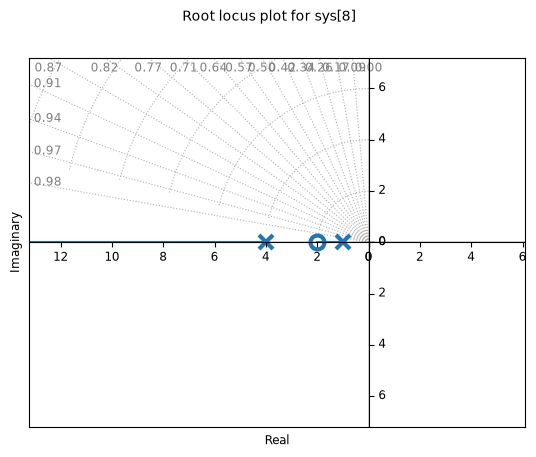

DC gain for OL= 4.0
Zeros of OL= [-2.+0.j]
Poles of OL= [-4.+0.j -1.+0.j]
Dominant stable OL pole(s): [-1.+0.j]
Dominant OL pole (p1) = (-1+0j)
Dominant OL pole (p1) in abs value = 1.0


In [4]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(L, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(L, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(L)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(L)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(L)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
p_do = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

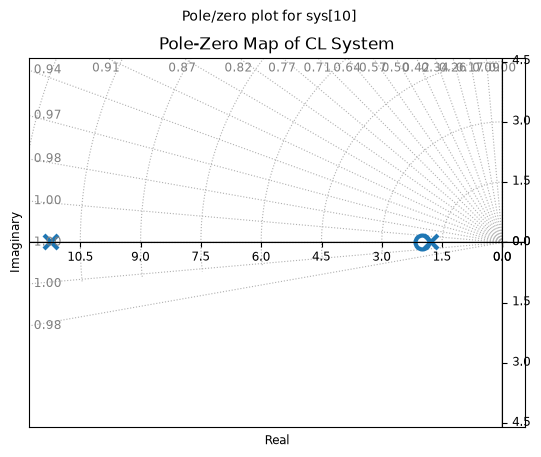

DC gain for CL= 0.8
Zeros of CL= [-2.+0.j]
Poles of CL= [-11.21699057+0.j  -1.78300943+0.j]
    Eigenvalue (pole)       Damping     Frequency
               -11.22             1         11.22
               -1.783             1         1.783
Natural frequency of poles (Wn) = [11.21699057  1.78300943]
Damping ratio zeta of poles (Z) = [1. 1.]
Poles = [-11.21699057+0.j  -1.78300943+0.j]
Poles of CL= [-11.21699057+0.j  -1.78300943+0.j]
Dominant stable CL pole(s): [-1.78300943+0.j]
Dominant CL pole (p1) = (-1.7830094339716982+0j)
Dominant CL pole (p1) in abs value = 1.7830094339716982


Dominant Pole: (-1.7830094339716982+0j)
Natural frequency (wn): 1.7830094339716982 rad/s
Damping ratio (zeta, z): 1.0
Decay rate (sigma): 1.7830094339716982 1/s
Damped frequency (wd): 0.0 rad/s


In [5]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(CL, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(CL)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(CL)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(CL)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(CL)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
p_d = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




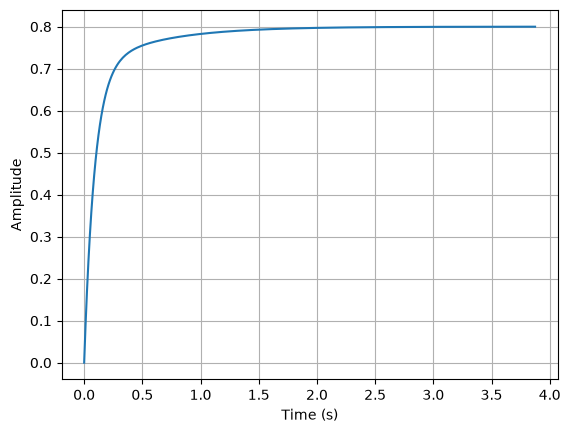

Rise Time (Tr): 0.31 seconds
Settling Time (Ts): 1.06 seconds
Peak Time (Tp): 3.87 seconds
Overshoot (%): 0.00%
Final Value = 0.8
Steasy state error (ess) = 0.19999999999999996


In [6]:
plt.figure()
t, y = ct.step_response(CL)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(CL)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')


In [7]:
# Type of the system = 0 
# So, Kp is specified, Kp = lim:s->0 G(s)Gc(s) 

Kp_old = np.abs(G(0))
print(f'Old velocity error constant (Kp_old) = {Kp_old}')

ess_old = 1/(Kp_old+1)
print(f'Old error (ess) = {ess_old}')

Old velocity error constant (Kp_old) = 4.0
Old error (ess) = 0.2


In [8]:
# Required Specification 
# ess = 0.01 

In [9]:
# Type of the system = 0
# So, Kp is specified, Kp = lim:s->0 G(s)Gc(s)

ess_new = 0.01 
print(f'Required error (ess) = {ess_new}')
Kp_new = (1 / ess_new) - 1 
print(f'Required velocity error constant (Kp_new) = {Kp_new}')

Required error (ess) = 0.01
Required velocity error constant (Kp_new) = 99.0


In [10]:
beta = Kp_new / Kp_old
print(f'Beta = {beta}')

# Nearest open loop pole
# -1/T = 10% of the nearest open or close loop pole
# P_do  np.real(p_do)
T = -1/(0.1*np.real(p_do))
print(f'T = {T}')

zc = 1/T
print(f'Zero of the lag compensator (zc) = {zc}')
pc = 1/(T*beta)
print(f'Pole of the lag compensator (pc) = {pc}')

# Lag Compensator transfer function without gain 
Gc = ct.tf([1, zc], [1, pc])
print(f'Lead Compensator Transfer Function without gain (Gc) = {Gc}')

# |Gc(s)| = 1 and -5 < angle(Gc(s)) < 0 
print(f'Open Loop Gain at required Pole Gc(Sd) = {Gc(p_do)}')
print(f'Open Loop Gain at required Pole in absolute form Gc(Sd) = {np.abs(Gc(p_do))}')
print(f'Open Loop Phase at required Pole Gc(Sd) = {np.angle(Gc(p_do))}')
print(f'Open Loop Phase at required Pole in Degrees Gc(Sd) = {np.rad2deg(np.angle(Gc(p_do)))}')

Beta = 24.75
T = 10.0
Zero of the lag compensator (zc) = 0.1
Pole of the lag compensator (pc) = 0.00404040404040404
Lead Compensator Transfer Function without gain (Gc) = <TransferFunction>: sys[15]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

    s + 0.1
  -----------
  s + 0.00404
Open Loop Gain at required Pole Gc(Sd) = (0.9036511156186612-0j)
Open Loop Gain at required Pole in absolute form Gc(Sd) = 0.9036511156186612
Open Loop Phase at required Pole Gc(Sd) = -0.0
Open Loop Phase at required Pole in Degrees Gc(Sd) = -0.0


In [11]:
# Lead compensator gain 
Kc = 1/(np.abs(G(p_d)*Gc(p_d)))
print(f'Lead Compensator Gain (Kc) = {Kc}')

Lead Compensator Gain (Kc) = 1.0570166714592584


In [12]:
Gc1 = Kc * Gc
print(f'Lead Compensator Transfer Function with gain (Gc1) = {Gc1}')

# |Gc(s)| = 1 and -5 < angle(Gc(s)) < 0 
print(f'Open Loop Gain at required Pole G(Sd) = {Gc(p_d)}')
print(f'Open Loop Gain at required Pole in absolute form G(Sd) = {np.abs(Gc(p_d))}')
print(f'Open Loop Phase at required Pole G(Sd) = {np.angle(Gc(p_d))}')
print(f'Open Loop Phase at required Pole in Degrees G(Sd) = {np.rad2deg(np.angle(Gc(p_d)))}')

Lead Compensator Transfer Function with gain (Gc1) = <TransferFunction>: sys[17]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  1.057 s + 0.1057
  ----------------
    s + 0.00404
Open Loop Gain at required Pole G(Sd) = (0.9460588721079074-0j)
Open Loop Gain at required Pole in absolute form G(Sd) = 0.9460588721079074
Open Loop Phase at required Pole G(Sd) = -0.0
Open Loop Phase at required Pole in Degrees G(Sd) = -0.0


In [13]:
# Type of system = 1 i.e. pole at origin = 1 
# so the velocity error constant, Kv = lim:s->0 sG(s)Gc(s)
kp = np.abs(G(0)*Gc1(0))
print(f'velocity error constant kp = {kp}')

ess = 1/(kp+1)
print(f'steady state error ess = {ess}')

velocity error constant kp = 104.64465047446659
steady state error ess = 0.009465694623521818


In [14]:
A3 = G*Gc1 
print(f'System Transfer Function with compensator A3(s) = {A3}')
A4 = A3 * H
print(f'open loop system transfer function with compensator A4(s) = {A4}')
A5 = ct.feedback(A3, 1)
print(f'Closed loop system transfer function with compensator A5(s) = {A5}')

System Transfer Function with compensator A3(s) = <TransferFunction>: sys[18]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

     8.456 s^2 + 17.76 s + 1.691
  ----------------------------------
  s^3 + 5.004 s^2 + 4.02 s + 0.01616
open loop system transfer function with compensator A4(s) = <TransferFunction>: sys[20]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

     8.456 s^2 + 17.76 s + 1.691
  ----------------------------------
  s^3 + 5.004 s^2 + 4.02 s + 0.01616
Closed loop system transfer function with compensator A5(s) = <TransferFunction>: sys[22]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

     8.456 s^2 + 17.76 s + 1.691
  ---------------------------------
  s^3 + 13.46 s^2 + 21.78 s + 1.707


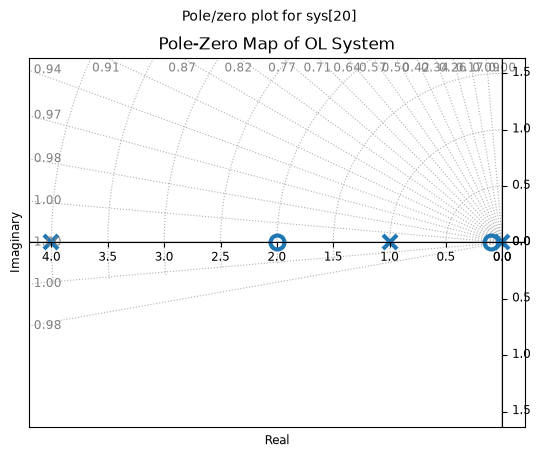

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


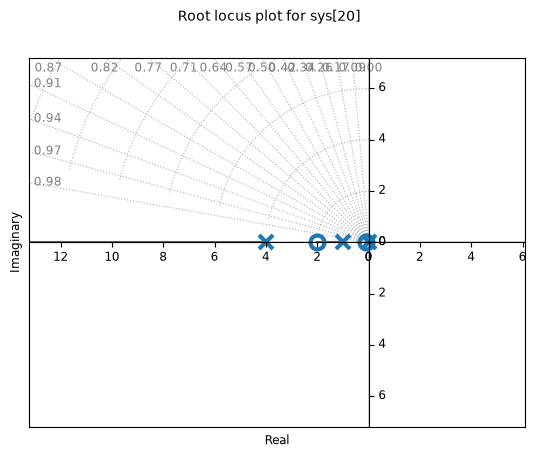

DC gain for OL= 104.64465047446659
Zeros of OL= [-2. +0.j -0.1+0.j]
Poles of OL= [-4.       +0.j -1.       +0.j -0.0040404+0.j]
Dominant stable OL pole(s): [-0.0040404+0.j]
Dominant OL pole (p1) = (-0.004040404040404041+0j)
Dominant OL pole (p1) in abs value = 0.004040404040404041


In [15]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A4, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(A4, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(A4)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(A4)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(A4)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

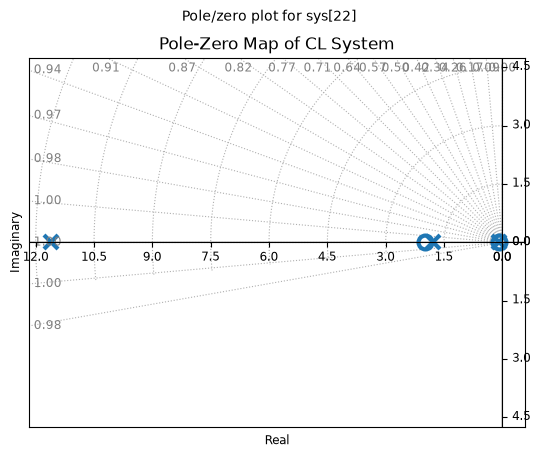

DC gain for CL= 0.9905343053764781
Zeros of CL= [-2. +0.j -0.1+0.j]
Poles of CL= [-11.59457503+0.j  -1.78300943+0.j  -0.08258931+0.j]
    Eigenvalue (pole)       Damping     Frequency
               -11.59             1         11.59
               -1.783             1         1.783
             -0.08259             1       0.08259
Natural frequency of poles (Wn) = [11.59457503  1.78300943  0.08258931]
Damping ratio zeta of poles (Z) = [1. 1. 1.]
Poles = [-11.59457503+0.j  -1.78300943+0.j  -0.08258931+0.j]
Poles of CL= [-11.59457503+0.j  -1.78300943+0.j  -0.08258931+0.j]
Dominant stable CL pole(s): [-0.08258931+0.j]
Dominant CL pole (p1) = (-0.08258930702374707+0j)
Dominant CL pole (p1) in abs value = 0.08258930702374707


Dominant Pole: (-0.08258930702374707+0j)
Natural frequency (wn): 0.08258930702374707 rad/s
Damping ratio (zeta, z): 1.0
Decay rate (sigma): 0.08258930702374707 1/s
Damped frequency (wd): 0.0 rad/s


In [16]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A5, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(A5)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(A5)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(A5)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(A5)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




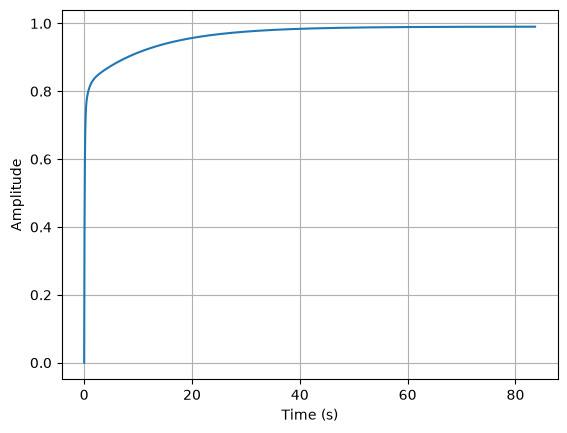

Rise Time (Tr): 6.86 seconds
Settling Time (Ts): 26.35 seconds
Peak Time (Tp): 83.64 seconds
Overshoot (%): 0.00%
Final Value = 0.9905343053764781
Steasy state error (ess) = 0.00946569462352187


In [17]:
plt.figure()
t, y = ct.step_response(A5)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(A5)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

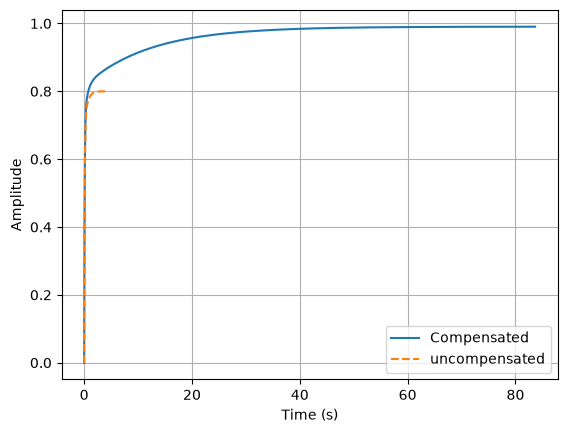

In [18]:
plt.figure()
t1, y1 = ct.step_response(A5)
t2, y2 = ct.step_response(CL)

plt.plot(t1, y1, label='Compensated')
plt.plot(t2, y2, label='uncompensated', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.show()